# Time-lag exploration — do we need a propagation lag in the reconstruction?

**Question.** The hybrid reconstruction is *instantaneous*: every hour, each goal's
WHACS forcing is mapped to the nearshore through a stationary SnapWave transfer
function, and the goal contributions are summed. Real wave energy needs time to
travel from the AoI boundary to a site — following O'Reilly et al. (2016, App. B):

$$\tau(f,\theta) = \frac{d_L}{C_g(f,h)},\qquad d_L = d_B\cos(\theta_{to}-\beta)$$

For a swell entering through the **northern** boundary and reaching the **southern**
buoys (Eurogeul, IJmuiden), the naive estimate is ~250 km / 9–11 m s⁻¹ ≈ **6–8 h**,
an order of magnitude larger than the 1 h time step. Does that show up as a timing
error in the storm peaks, and would a goal→site lag fix it?

**Approach**

1. Travel-time physics: finite-depth group velocity integrated over the real bathymetry,
   goal → buoy (section 2).
2. *Which* goals actually feed each buoy — per-goal energy shares from the metamodel
   (section 3).
3. Does WHACS already carry the arrival time along the boundary? (section 4)
4. Statistical timing test 2010–2015: lagged correlation and storm-peak timing,
   split by offshore direction regime (section 5).
5. Lag-corrected reconstruction — each goal contribution delayed by its own
   $\tau_{g,s}(t)$ — scored against the buoys (section 6).
6. Storm case studies (Xaver Dec 2013, Jan 2012, Oct 2014), including a time-varying
   water-level experiment (section 7).

Bulk mode only (`spectral=False`, WHACS partition `-1`), `mda_n = 450`.

**Prerequisites:** fitted models (06), processed buoys (10), cached bulk reconstruction at
the buoys (10). Sections 3, 6 and 7 re-run the metamodel **goal by goal only over a set of
storm windows** (a few minutes on CPU, cached under `tmp/storm_validation/`) — sections 1, 4
and 5 only use the existing cache.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray
import xarray as xr
from IPython.display import display
from scipy.signal import find_peaks
from utils.config import PATHS, load_goals, open_offshore_waves, resolve
from utils.model import metamodel as mm
from utils.observation import onshore_sites as obs

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)

## Configuration

In [ ]:
period = slice("2010", "2015")  # matches the 10 reconstruction cache
offshore_name = "WHACS"
mda_n = 450
pca_variance = 0.99

# All 9 configured buoys go into the per-goal cube (same site set as notebook 10,
# so the bulk cache is a hit). Analysis drops AmelanderZeegat_1_2 (co-located
# duplicate of 1_1) and ZandmoterBoeiNoord (~1700 valid samples in 2010-2015).
buoy_instruments = [
    "AmelanderZeegat_1_1",
    "AmelanderZeegat_1_2",
    "EierlandseGat",
    "EurogeulE13",
    "IJmuidenMunitiestort_1",
    "PettenMeetraai01",
    "StortemelkWest",
    "WestereemsWest",
    "ZandmoterBoeiNoord",
]
sites = [obs.snapwave_site_id(i) for i in buoy_instruments]
analysis_buoys = [  # ordered south -> north-east along the coast
    "EurogeulE13",
    "IJmuidenMunitiestort_1",
    "PettenMeetraai01",
    "EierlandseGat",
    "StortemelkWest",
    "AmelanderZeegat_1_1",
    "WestereemsWest",
]
south_buoys = ["EurogeulE13", "IJmuidenMunitiestort_1"]

# Raw RWS exports — only needed for Tm-10 (the processed files keep hs/dir only)
raw_buoy_files = {
    "EurogeulE13": "inputs/Observations/raw/eurogeul.e13-Eurogeul_E13.nc",
    "IJmuidenMunitiestort_1": "inputs/Observations/raw/ijmuiden.munitiestort.1-IJmuiden_munitiestort_1.nc",
    "PettenMeetraai01": "inputs/Observations/raw/petten.meetraai1-Petten_meetraai_01.nc",
    "EierlandseGat": "inputs/Observations/raw/eierlandsegat-Eierlandse_Gat.nc",
    "StortemelkWest": "inputs/Observations/raw/stortemelk.west-Stortemelk_west.nc",
    "AmelanderZeegat_1_1": "inputs/Observations/raw/amelanderzeegat.1.1-Amelander_zeegat_1_1.nc",
    "WestereemsWest": "inputs/Observations/raw/westereems.west-Westereems_west.nc",
}

# Offshore direction regimes (WHACS bulk wave-from direction at goal 7, northern boundary)
regimes = {"north (300-40°)": (300.0, 40.0), "west (200-300°)": (200.0, 300.0)}
regime_goal = 7

# Case studies (section 7) — search ranges; each is centred on its WHACS G7 peak and
# always included in the storm set
case_storms = {
    "Xaver, Dec 2013": slice("2013-12-04", "2013-12-09"),
    "Jan 2012": slice("2012-01-04", "2012-01-09"),
    "Oct 2014": slice("2014-10-20", "2014-10-25"),
}
# Storm set for sections 3 and 6: the strongest events (WHACS Hs at goal 7) per regime
n_storms_per_regime = {"north (300-40°)": 10, "west (200-300°)": 5}
storm_half_window = (
    pd.Timedelta("3D"),
    pd.Timedelta("2D"),
)  # before / after peak (1st day = lag spin-up)

storm_cache = resolve("tmp/storm_validation")
storm_cache.mkdir(parents=True, exist_ok=True)

## 1 · Data

- **Buoys** — processed `hs` (10-min → hourly mean) and **Tm-10** from the raw RWS export
  (quality code `00`), the only period-type statistic these buoys provide.
- **Bulk reconstruction** — `mm.reconstruct(spectral=False)` (cache hit from notebook 10).
- **WHACS** bulk forcing at every goal, and **CODEC** water level at every goal.

In [ ]:
def buoy_hourly(instrument_id: str) -> pd.Series:
    ds = xr.open_dataset(resolve(f"inputs/Observations/processed/{instrument_id}.nc"))
    return ds["hs"].sel(time=period).to_series().resample("1h").mean()


def buoy_tm10_hourly(raw_path: str) -> pd.Series:
    raw = xr.open_dataset(resolve(raw_path))[
        ["Tm-10", "Tm-10__WaarnemingMetadata_Kwaliteitswaardecode"]
    ].sel(time=period)
    tm = raw["Tm-10"].where(
        raw["Tm-10__WaarnemingMetadata_Kwaliteitswaardecode"] == "00"
    )
    tm = tm.where((tm > 0) & (tm < 30))
    return tm.to_series().resample("1h").mean()


obs_hs = pd.DataFrame({b: buoy_hourly(b) for b in analysis_buoys})
obs_tm10 = pd.DataFrame({b: buoy_tm10_hourly(p) for b, p in raw_buoy_files.items()})

bulk = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
    save_spectra=False,
)
rec_hs = bulk["hs"].to_pandas().rename(columns=lambda s: s.removeprefix("buoy_"))

offshore = open_offshore_waves(offshore_name)
whacs = offshore[["hs", "tp", "dir"]].sel(time=period).load()
codec_wl = (
    xr.open_zarr(resolve("inputs/CODEC/processed/Netherlands_CODEC_goal.zarr"))
    .waterlevel.sel(time=period)
    .load()
)

goals = load_goals()
goal_ids = [int(g) for g in goals]
goal_lonlat = pd.DataFrame(
    {
        g: (goals[str(g)]["target"]["longitude"], goals[str(g)]["target"]["latitude"])
        for g in goal_ids
    },
    index=["lon", "lat"],
).T
buoy_lonlat = pd.DataFrame(
    {
        s.removeprefix("buoy_"): (
            float(bulk.site_longitude.sel(sites=s)),
            float(bulk.site_latitude.sel(sites=s)),
        )
        for s in sites
    },
    index=["lon", "lat"],
).T

print("buoy hourly obs:", obs_hs.notna().sum().to_dict())
print("bulk reconstruction:", dict(bulk.sizes))

buoy hourly obs: {'EurogeulE13': 44792, 'IJmuidenMunitiestort_1': 49750, 'PettenMeetraai01': 17550, 'EierlandseGat': 47503, 'StortemelkWest': 48134, 'AmelanderZeegat_1_1': 27771, 'WestereemsWest': 47715}
bulk reconstruction: {'time': 52584, 'sites': 9}


In [ ]:
def in_sector(direction, lo, hi):
    # Nautical sector lo -> hi clockwise (may wrap through North)
    d = np.mod(direction, 360.0)
    return (d >= lo) & (d < hi) if lo < hi else (d >= lo) | (d < hi)


dir_reg = whacs["dir"].sel(goal=regime_goal).to_series()
regime_mask = {
    name: pd.Series(in_sector(dir_reg.values, *lims), index=dir_reg.index)
    for name, lims in regimes.items()
}
regime_mask["all"] = pd.Series(True, index=dir_reg.index)
print({k: f"{v.mean():.0%} of hours" for k, v in regime_mask.items()})

{'north (300-40°)': '43% of hours', 'west (200-300°)': '39% of hours', 'all': '100% of hours'}


## 2 · Travel-time physics

Linear-theory group speed $C_g = n\,c$ with $\omega^2 = gk\tanh kh$. For each goal → buoy
pair, the travel time is integrated along the straight path over the case bathymetry
(`topobathy_file`), $t_{path}(T) = \int ds / C_g(T, h(s))$, tabulated over $T$. The lag
applied to one goal contribution at time $t$ is then the paper's projection:

$$\tau_{g,s}(t) = \max\!\big[\cos(\theta_{to,g}(t) - \beta_{g,s}),\,0\big]\; t_{path,g,s}\big(T_{p,g}(t)\big)$$

with $\theta_{to}$ the goal's WHACS bulk direction (heading-to), $\beta$ the bearing goal → site,
and $T_p$ the goal's WHACS peak period. Energy travelling *away* from a site gets no lag
(it cannot reach it along that ray anyway).

Note the shallow-water effect: at 20–40 m depth, 8–14 s waves travel **faster** than in
deep water ($C_g$ peaks at $kh \approx 1.2$), so deep-water $C_g$ would overestimate the lag.

In [ ]:
G = 9.81
R_EARTH = 6371e3
T_GRID = np.arange(3.0, 20.01, 0.5)


def group_velocity(T, h):
    # Linear-theory group speed (m/s); Newton iterations on kh tanh(kh) = w^2 h / g
    T = np.asarray(T, float)
    h = np.asarray(h, float)
    w = 2 * np.pi / T
    k0h = w**2 * h / G
    kh = np.where(k0h < 1, np.sqrt(k0h) * (1 + k0h / 6), k0h)
    for _ in range(30):
        kh = kh - (kh * np.tanh(kh) - k0h) / (np.tanh(kh) + kh / np.cosh(kh) ** 2)
    c = w / (kh / h)
    return 0.5 * (1 + 2 * kh / np.sinh(2 * kh)) * c


def great_circle(lon1, lat1, lon2, lat2):
    # Distance (m) and initial bearing (deg clockwise from N), point 1 -> point 2
    p1, p2, dl = np.radians(lat1), np.radians(lat2), np.radians(lon2 - lon1)
    d = np.arccos(
        np.clip(np.sin(p1) * np.sin(p2) + np.cos(p1) * np.cos(p2) * np.cos(dl), -1, 1)
    )
    b = np.degrees(
        np.arctan2(
            np.cos(p2) * np.sin(dl),
            np.cos(p1) * np.sin(p2) - np.sin(p1) * np.cos(p2) * np.cos(dl),
        )
    )
    return d * R_EARTH, np.mod(b, 360.0)


bathy = rioxarray.open_rasterio(resolve(PATHS["topobathy_file"])).squeeze(drop=True)


def path_travel_time(lon0, lat0, lon1, lat1, n=200, h_min=2.0):
    # Travel time (h) over T_GRID along the straight path, and its fraction over land
    lons, lats = np.linspace(lon0, lon1, n), np.linspace(lat0, lat1, n)
    z = bathy.interp(
        x=xr.DataArray(lons, dims="s"), y=xr.DataArray(lats, dims="s")
    ).values
    land = float(np.mean(~(z < 0)))
    h = np.clip(np.where(np.isnan(z), h_min, -z), h_min, None)
    dist, _ = great_circle(lon0, lat0, lon1, lat1)
    h_mid = 0.5 * (h[1:] + h[:-1])
    cg = group_velocity(T_GRID[:, None], h_mid[None, :])
    return (dist / (n - 1) / cg).sum(axis=1) / 3600.0, land, dist


tt, beta, dist, land = [
    np.zeros((len(goal_ids), len(sites)) + s) for s in [(len(T_GRID),), (), (), ()]
]
for i, g in enumerate(goal_ids):
    for j, s in enumerate(sites):
        b = s.removeprefix("buoy_")
        g0, b0 = goal_lonlat.loc[g], buoy_lonlat.loc[b]
        tt[i, j], land[i, j], dist[i, j] = path_travel_time(
            g0.lon, g0.lat, b0.lon, b0.lat
        )
        beta[i, j] = great_circle(g0.lon, g0.lat, b0.lon, b0.lat)[1]

travel = xr.Dataset(
    {
        "tt_path": (("goal", "sites", "T"), tt),
        "beta": (("goal", "sites"), beta),
        "dist_km": (("goal", "sites"), dist / 1e3),
        "land_frac": (("goal", "sites"), land),
    },
    coords={"goal": goal_ids, "sites": sites, "T": T_GRID},
)

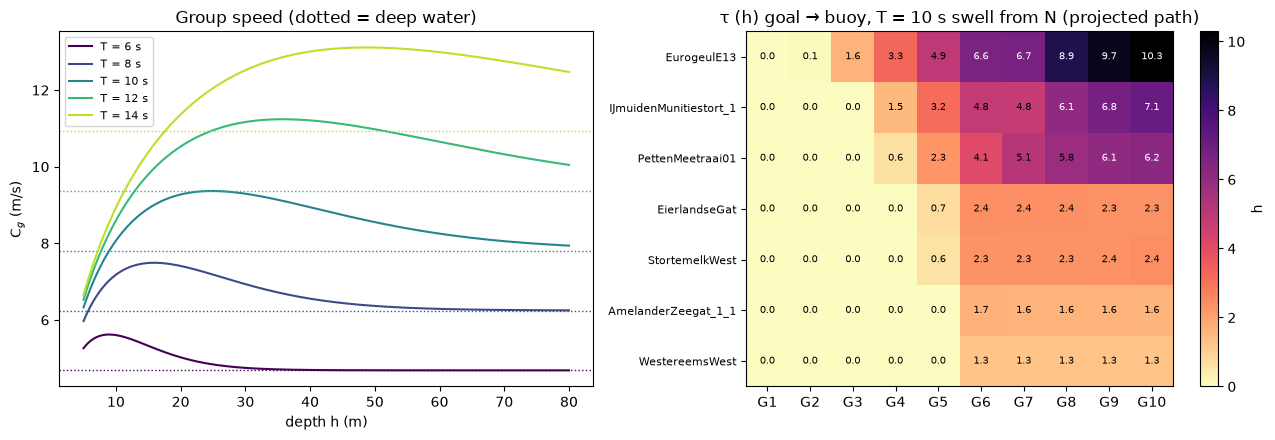

Straight-line distance goal 7 -> Eurogeul: 251 km, unprojected path travel time at T=10 s: 7.6 h, 0% of that path over land


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

h = np.linspace(5, 80, 200)
for T, col in zip([6, 8, 10, 12, 14], plt.cm.viridis(np.linspace(0, 0.9, 5))):
    axes[0].plot(h, group_velocity(T, h), color=col, label=f"T = {T} s")
    axes[0].axhline(G * T / (4 * np.pi), color=col, ls=":", lw=1)
axes[0].set(
    xlabel="depth h (m)",
    ylabel="C$_g$ (m/s)",
    title="Group speed (dotted = deep water)",
)
axes[0].legend(fontsize=8)

# Travel time at T = 10 s for a swell *from the north* (heading 180°), goal -> buoy
theta_to = 180.0
proj = np.cos(np.radians(theta_to - travel.beta)).clip(min=0)
tau_n = (proj * travel.tt_path.sel(T=10.0)).sel(
    sites=[f"buoy_{b}" for b in analysis_buoys]
)
im = axes[1].imshow(tau_n.values.T, cmap="magma_r", aspect="auto", vmin=0)
axes[1].set_xticks(range(len(goal_ids)), [f"G{g}" for g in goal_ids])
axes[1].set_yticks(range(len(analysis_buoys)), analysis_buoys, fontsize=8)
for i in range(len(goal_ids)):
    for j in range(len(analysis_buoys)):
        axes[1].text(
            i,
            j,
            f"{tau_n.values[i, j]:.1f}",
            ha="center",
            va="center",
            fontsize=7,
            color="w" if tau_n.values[i, j] > 6 else "k",
        )
axes[1].set_title("τ (h) goal → buoy, T = 10 s swell from N (projected path)")
plt.colorbar(im, ax=axes[1], label="h")
plt.tight_layout()
plt.show()

print(
    "Straight-line distance goal 7 -> Eurogeul: "
    f"{float(travel.dist_km.sel(goal=7, sites='buoy_EurogeulE13')):.0f} km, "
    f"unprojected path travel time at T=10 s: {float(travel.tt_path.sel(goal=7, sites='buoy_EurogeulE13', T=10.0)):.1f} h, "
    f"{float(travel.land_frac.sel(goal=7, sites='buoy_EurogeulE13')):.0%} of that path over land"
)

The **naive** picture is there in the table: G7 → Eurogeul is 251 km of open water, ~7.6 h
for a 10 s swell (~6.5 h once projected on a swell from the north). But a lag only matters
for energy that really travels that path — what matters is *which goals actually deliver
energy to each buoy* in the reconstruction.

## 3 · Storm set and per-goal contributions

Each goal's metamodel was trained with **Hs = 1 at that goal and 0 everywhere else**
(`templates-metamodel/hs.txt`), and the reconstruction linearly sums the goal spectra. So
the reconstruction at a site is a sum of goal contributions — exactly what a goal→site lag
would act on.

We pick a storm set (strongest WHACS Hs peaks at G7 per regime, ≥ 7 days apart, plus the
case studies) and rebuild the goal contributions over those windows only, with
`mm._predict_offshore(..., partition=-1)` — each goal's models are loaded once and predict
all windows in one call. Then: check that `mm._wavespectra_sum` of the contributions
reproduces the cached bulk reconstruction, and compute each goal's **energy share**
($\sum_t H_{s,g}^2 / \sum_{t,g} H_{s,g}^2$) at each buoy.

In [ ]:
hs_g7 = whacs["hs"].sel(goal=regime_goal).to_series()
storm_peaks = {}
for name, n_take in n_storms_per_regime.items():
    cand = hs_g7[regime_mask[name]].sort_values(ascending=False)
    picked = []
    for t in cand.index:
        if all(abs(t - p) > pd.Timedelta("7D") for p in picked):
            picked.append(t)
        if len(picked) == n_take:
            break
    for t in picked:
        storm_peaks[t] = name
for name, tw in case_storms.items():
    t = hs_g7[tw].idxmax()
    storm_peaks = {
        k: v for k, v in storm_peaks.items() if abs(k - t) > pd.Timedelta("5D")
    }
    storm_peaks[t] = f"case: {name}"

storm_table = (
    pd.DataFrame(
        [
            {
                "peak": t,
                "set": lab,
                "hs_G7": hs_g7[t],
                "dir_G7": dir_reg[t],
                "start": t - storm_half_window[0],
                "stop": t + storm_half_window[1],
            }
            for t, lab in storm_peaks.items()
        ]
    )
    .sort_values("peak")
    .reset_index(drop=True)
)
storm_table["regime"] = np.where(
    in_sector(storm_table.dir_G7.values, *regimes["north (300-40°)"]),
    "north (300-40°)",
    np.where(
        in_sector(storm_table.dir_G7.values, *regimes["west (200-300°)"]),
        "west (200-300°)",
        "other",
    ),
)
storm_table.round(2)

,peak,set,hs_G7,dir_G7,start,stop,regime
0,2010-10-24 03:00:00,north (300-40°),4.62,328.1,2010-10-21 03:00:00,2010-10-26 03:00:00,north (300-40°)
1,2010-11-12 10:00:00,west (200-300°),5.02,266.4,2010-11-09 10:00:00,2010-11-14 10:00:00,west (200-300°)
2,2011-07-23 23:00:00,north (300-40°),4.31,310.6,2011-07-20 23:00:00,2011-07-25 23:00:00,north (300-40°)
3,2012-01-05 11:00:00,case: Jan 2012,5.29,299.6,2012-01-02 11:00:00,2012-01-07 11:00:00,west (200-300°)
4,2012-01-22 01:00:00,north (300-40°),4.55,300.5,2012-01-19 01:00:00,2012-01-24 01:00:00,north (300-40°)
5,2012-02-15 08:00:00,north (300-40°),4.30,334.9,2012-02-12 08:00:00,2012-02-17 08:00:00,north (300-40°)
6,2012-11-25 14:00:00,west (200-300°),5.67,233.8,2012-11-22 14:00:00,2012-11-27 14:00:00,west (200-300°)
7,2013-10-28 11:00:00,west (200-300°),4.99,221.7,2013-10-25 11:00:00,2013-10-30 11:00:00,west (200-300°)
8,2013-12-05 19:00:00,"case: Xaver, Dec 2013",6.77,312.8,2013-12-02 19:00:00,2013-12-07 19:00:00,north (300-40°)
9,2014-10-22 06:00:00,case: Oct 2014,5.09,323.1,2014-10-19 06:00:00,2014-10-24 06:00:00,north (300-40°)


In [ ]:
storm_times = pd.DatetimeIndex(
    sorted(
        set().union(
            *[
                pd.date_range(r.start, r.stop, freq="1h")
                for r in storm_table.itertuples()
            ]
        )
    )
)
storm_times = storm_times[storm_times.isin(whacs.time.values)]
cube_path = (
    storm_cache
    / f"goal_cube_bulk_n{mda_n}_{len(storm_table)}storms_{storm_times[0]:%Y%m%d}-{storm_times[-1]:%Y%m%d}.nc"
)

if cube_path.is_file():
    cube = xr.open_dataset(cube_path).load()
else:
    off_storms = offshore.sel(time=storm_times)
    chunks = []
    for g in mm._goals(None):
        models = mm.load_models(g, mda_n, pca_variance=pca_variance)
        pred = mm._predict_offshore(
            off_storms,
            g,
            mda_n,
            sites,
            partition=mm.BULK_PARTITION,
            pca_variance=pca_variance,
            models=models,
        )
        if pred is not None:
            chunks.append(pred.expand_dims(goal=[int(g)]).load())
        del models
        mm._release_gp_memory()
    cube = xr.concat(chunks, dim="goal", join="outer").reindex(time=storm_times)[
        ["hs", "tp", "dir", "spr"]
    ]
    cube.to_netcdf(cube_path)
print(
    f"{len(storm_table)} storms, {cube.sizes['time']} hours, {cube.sizes['goal']} goals -> {cube_path.name}"
)

13 storms, 1573 hours, 10 goals -> goal_cube_bulk_n450_13storms_20101021-20150907.nc


In [ ]:
# Sanity check: summing the per-goal contributions reproduces the cached bulk reconstruction
chk, _ = mm._wavespectra_sum(cube.expand_dims(partition=[-1]), sites)
print(
    "max |Hs(sum of goals) - Hs(cached bulk)| over all storm hours =",
    f"{float(np.abs(chk.hs - bulk.hs.sel(time=chk.time)).max()):.2e} m",
)

max |Hs(sum of goals) - Hs(cached bulk)| over all storm hours = 2.84e-04 m


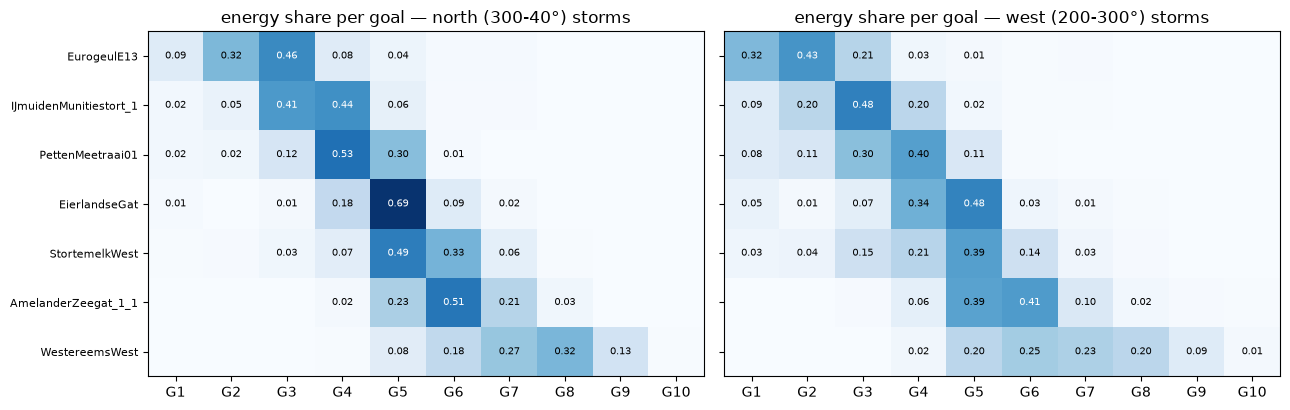

In [ ]:
energy = (cube["hs"] ** 2).fillna(0.0)
storm_regime = pd.Series("other", index=cube.time.to_index())
for r in storm_table.itertuples():
    storm_regime[r.start : r.stop] = r.regime
fig, axes = plt.subplots(1, len(regimes), figsize=(13, 4.2), sharey=True)
shares = {}
for ax, name in zip(axes, regimes):
    e = energy.sel(time=storm_regime.index[storm_regime == name])
    share = (e.sum("time") / e.sum(["time", "goal"])).sel(
        sites=[f"buoy_{b}" for b in analysis_buoys]
    )
    shares[name] = share
    ax.imshow(share.values.T, cmap="Blues", vmin=0, vmax=0.7, aspect="auto")
    for i in range(share.sizes["goal"]):
        for j in range(share.sizes["sites"]):
            v = float(share.values[i, j])
            if v >= 0.01:
                ax.text(
                    i,
                    j,
                    f"{v:.2f}",
                    ha="center",
                    va="center",
                    fontsize=7,
                    color="w" if v > 0.4 else "k",
                )
    ax.set_xticks(range(len(goal_ids)), [f"G{g}" for g in goal_ids])
    ax.set_title(f"energy share per goal — {name} storms")
axes[0].set_yticks(range(len(analysis_buoys)), analysis_buoys, fontsize=8)
plt.tight_layout()
plt.show()

**Southern buoys are fed by the closest western goals** (Eurogeul by G2/G3, IJmuiden by
G3/G4) even when the waves come from the north; the northern goals G6–G10 contribute
almost nothing there. The metamodel already "knows" the geometry (SnapWave refraction +
the land shadow of North Holland/the Wadden islands), so the long north→south path is not
taken *inside* the AoI at all — it happens **outside**, in WHACS, before the energy reaches
G2–G4.

## 4 · Does WHACS already carry the arrival time along the boundary?

If the north→south propagation lives in WHACS, the goal time series should be lagged
relative to each other. Lagged correlation of WHACS Hs at every goal against goal 7, for
the northern regime and Hs(G7) > 1.5 m.

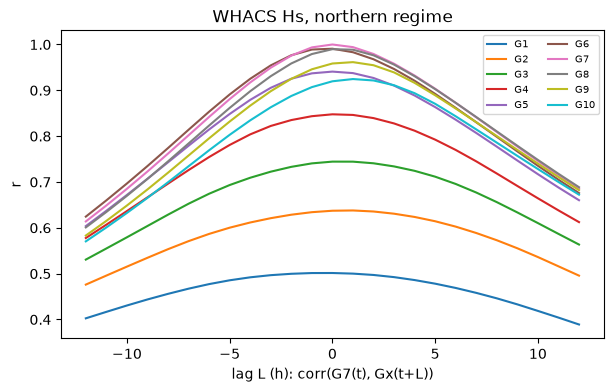

,lag_vs_G7_h,r_max,dist_to_G7_km
goal,,,
1,-0.44,0.501,344
2,0.71,0.638,274
3,0.48,0.744,213
4,0.25,0.848,149
5,0.04,0.941,86
6,-0.31,0.991,33
7,0.02,1.000,0
8,0.40,0.990,33
9,0.81,0.962,65


In [ ]:
lags = np.arange(-12, 13)


def lagged_corr(
    ref: pd.Series, other: pd.Series, mask: pd.Series, lags=lags, ref_min=1.5
):
    # corr(ref(t), other(t + L)) for each L
    out = []
    for L in lags:
        o = other.shift(-L)
        m = mask & ref.notna() & o.notna() & (ref > ref_min)
        out.append(np.corrcoef(ref[m], o[m])[0, 1] if m.sum() > 50 else np.nan)
    return np.array(out)


hs_goal = whacs["hs"].to_pandas()
rows = []
fig, ax = plt.subplots(figsize=(7, 4))
for g in goal_ids:
    c = lagged_corr(hs_goal[regime_goal], hs_goal[g], regime_mask["north (300-40°)"])
    L = lags[np.nanargmax(c)]
    # sub-hour peak by parabolic interpolation around the max
    k = np.nanargmax(c)
    if 0 < k < len(c) - 1:
        L = lags[k] + 0.5 * (c[k - 1] - c[k + 1]) / (c[k - 1] - 2 * c[k] + c[k + 1])
    rows.append(
        {
            "goal": g,
            "lag_vs_G7_h": round(float(L), 2),
            "r_max": round(float(np.nanmax(c)), 3),
            "dist_to_G7_km": round(
                great_circle(*goal_lonlat.loc[regime_goal], *goal_lonlat.loc[g])[0]
                / 1e3
            ),
        }
    )
    ax.plot(lags, c, label=f"G{g}")
ax.set(
    xlabel="lag L (h): corr(G7(t), Gx(t+L))",
    ylabel="r",
    title="WHACS Hs, northern regime",
)
ax.legend(ncol=2, fontsize=7)
plt.show()
display(pd.DataFrame(rows).set_index("goal"))

WHACS (a dynamic North Sea model) shifts the storm signal along the boundary by only
**~0.5–1.5 h** between G7 and G2–G3 under northern forcing. Two things are going on: the
boundary forcing already contains the propagation, and in a northern storm much of the
sea state is *locally generated* by the same wind field over the whole southern North Sea
(it does not travel from G7 at all). Either way, what the instantaneous reconstruction
misses is only the short path **G2–G4 → buoy**, i.e. ~50–100 km ≈ 1.5–3 h.

## 5 · Statistical timing test (2010–2015)

**5a. Lagged correlation** between buoy Hs and the bulk reconstruction shifted by $L$:
$\mathrm{corr}(H_{obs}(t), H_{rec}(t-L))$ for buoy Hs > 1.5 m. A positive best $L$ means the
reconstruction is **early** (needs a delay).

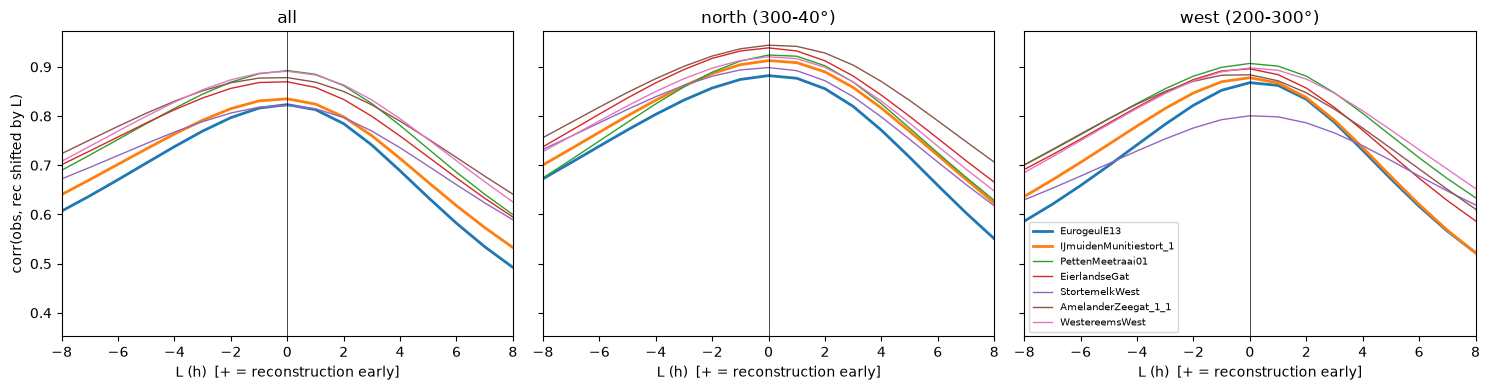

regime,all,north (300-40°),west (200-300°)
buoy,,,
EurogeulE13,-0.09,0.09,0.23
IJmuidenMunitiestort_1,-0.22,0.16,-0.07
PettenMeetraai01,-0.04,0.33,0.09
EierlandseGat,-0.38,0.00,-0.23
StortemelkWest,-0.16,-0.07,0.29
AmelanderZeegat_1_1,-0.41,0.26,-0.43
WestereemsWest,-0.15,0.16,0.12


In [ ]:
def lag_curve(o: pd.Series, r: pd.Series, mask: pd.Series, lags=lags, obs_min=1.5):
    out = []
    for L in lags:
        rs = r.shift(L)
        m = mask & o.notna() & rs.notna() & (o > obs_min)
        out.append(np.corrcoef(o[m], rs[m])[0, 1] if m.sum() > 50 else np.nan)
    return np.array(out)


def peak_lag(c, lags=lags):
    k = np.nanargmax(c)
    if 0 < k < len(c) - 1 and np.all(np.isfinite(c[k - 1 : k + 2])):
        return lags[k] + 0.5 * (c[k - 1] - c[k + 1]) / (c[k - 1] - 2 * c[k] + c[k + 1])
    return float(lags[k])


fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
rows = []
for ax, name in zip(axes, ["all", *regimes]):
    for b in analysis_buoys:
        c = lag_curve(obs_hs[b], rec_hs[b], regime_mask[name])
        ax.plot(lags, c, label=b, lw=2 if b in south_buoys else 1)
        rows.append(
            {
                "buoy": b,
                "regime": name,
                "best_lag_h": round(peak_lag(c), 2),
                "r(0)": round(c[lags == 0][0], 3),
                "r(best)": round(np.nanmax(c), 3),
            }
        )
    ax.axvline(0, color="k", lw=0.5)
    ax.set(title=name, xlabel="L (h)  [+ = reconstruction early]", xlim=(-8, 8))
axes[0].set_ylabel("corr(obs, rec shifted by L)")
axes[-1].legend(fontsize=7)
plt.tight_layout()
plt.show()
lagcorr = (
    pd.DataFrame(rows)
    .pivot(index="buoy", columns="regime", values="best_lag_h")
    .loc[analysis_buoys]
)
lagcorr

**5b. Storm-peak timing.** Peaks of buoy Hs > 2.5 m (≥ 72 h apart); timing difference
$\Delta t = t_{peak,obs} - t_{peak,rec}$ (3 h running mean, ±18 h window). Peaks with a buoy
gap within ±3 h are discarded — buoys often drop out right at the storm peak, which would
otherwise fake large timing errors.

count                                median                                  mean                      
regime                 north (300-40°) other west (200-300°) north (300-40°) other west (200-300°) north (300-40°) other west (200-300°)
buoy                                                                                                                                    
EurogeulE13                       32.0   8.0            89.0             0.5   0.0             0.0            0.38  0.00           -1.73
IJmuidenMunitiestort_1            34.0   7.0            96.0             0.0  -3.0             0.0            0.26 -1.29           -1.14
PettenMeetraai01                  19.0   NaN            28.0             0.0   NaN             0.0           -0.68   NaN           -1.25
EierlandseGat                     46.0   5.0            95.0             0.0  -3.0            -1.0            0.02 -5.60           -1.17
StortemelkWest                    47.0   2.0            58.0             0.0  -2.0             0.0           -0.68 -2.00           -1.02
AmelanderZeegat_1_1               38.0   8.0            41.0             0.0  -3.5            -1.0            0.21 -4.12           -2.17
WestereemsWest                    62.0   2.0            38.0             0.0   1.0            -0.5           -0.79  1.00           -1.53

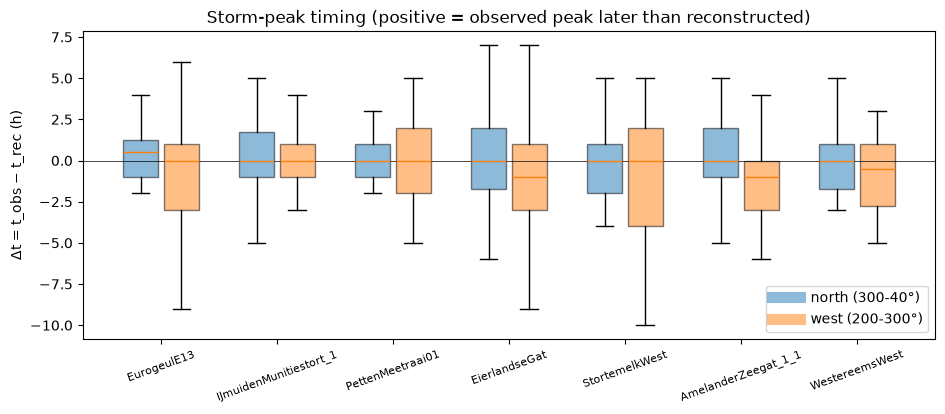

In [ ]:
def peak_events(o_df: pd.DataFrame, r_df: pd.DataFrame, hs_min=2.5, half_window="18h"):
    rows = []
    hw = pd.Timedelta(half_window)
    for b in analysis_buoys:
        o, r = o_df[b], r_df[b]
        pk, _ = find_peaks(o.fillna(0).values, height=hs_min, distance=72)
        for p in pk:
            t = o.index[p]
            if o[t - pd.Timedelta("3h") : t + pd.Timedelta("3h")].isna().any():
                continue
            ow, rw = o[t - hw : t + hw], r[t - hw : t + hw]
            if ow.notna().sum() < 30 or rw.notna().sum() < 30:
                continue
            to = ow.rolling(3, center=True).mean().idxmax()
            tr = rw.rolling(3, center=True).mean().idxmax()
            rows.append(
                {
                    "buoy": b,
                    "time": t,
                    "hs_obs": o[t],
                    "hs_rec_peak": rw.max(),
                    "dt_h": (to - tr) / pd.Timedelta("1h"),
                    "tm10_obs": obs_tm10[b].get(t, np.nan) if b in obs_tm10 else np.nan,
                    "dir_G7": dir_reg.get(t, np.nan),
                }
            )
    ev = pd.DataFrame(rows)
    ev["regime"] = "other"
    for name, lims in regimes.items():
        ev.loc[in_sector(ev["dir_G7"].values, *lims), "regime"] = name
    return ev


events = peak_events(obs_hs, rec_hs)
summary_ev = (
    events.groupby(["regime", "buoy"])["dt_h"].agg(["count", "median", "mean"]).round(2)
)
display(summary_ev.unstack(0).loc[analysis_buoys])

fig, ax = plt.subplots(figsize=(11, 4))
pos = np.arange(len(analysis_buoys))
for k, (name, col) in enumerate(zip(regimes, ["tab:blue", "tab:orange"])):
    data = [
        events.query("buoy == @b and regime == @name")["dt_h"].values
        for b in analysis_buoys
    ]
    bp = ax.boxplot(
        data,
        positions=pos + (k - 0.5) * 0.35,
        widths=0.3,
        patch_artist=True,
        showfliers=False,
    )
    for patch in bp["boxes"]:
        patch.set_facecolor(col)
        patch.set_alpha(0.5)
    ax.plot([], [], color=col, lw=8, alpha=0.5, label=name)
ax.axhline(0, color="k", lw=0.5)
ax.set_xticks(pos, analysis_buoys, rotation=20, fontsize=8)
ax.set_ylabel("Δt = t_obs − t_rec (h)")
ax.set_title("Storm-peak timing (positive = observed peak later than reconstructed)")
ax.legend()
plt.show()

In [ ]:
# Peak amplitude: how much of the storm peak does the reconstruction get?
amp = (
    events.assign(ratio=events.hs_rec_peak / events.hs_obs)
    .groupby(["buoy", "regime"])["ratio"]
    .median()
    .unstack()
)
amp.loc[analysis_buoys].round(2)

regime,north (300-40°),other,west (200-300°)
buoy,,,
EurogeulE13,0.87,0.69,0.71
IJmuidenMunitiestort_1,0.78,0.67,0.74
PettenMeetraai01,0.84,NaN,0.73
EierlandseGat,0.87,0.61,0.74
StortemelkWest,0.95,0.78,0.77
AmelanderZeegat_1_1,0.86,0.69,0.71
WestereemsWest,0.89,0.80,0.74


## 6 · Lag-corrected reconstruction

Each goal contribution (hs, tp, spr, dir) at each site is delayed by its own
$\tau_{g,s}(t)$ from section 2: $X_{g,s}(t) \leftarrow X_{g,s}(t - \tau_{g,s}(t))$ (energy $H_s^2$
interpolated linearly in time; direction through its u/v components), then the goals are
summed with the same `mm._wavespectra_sum` as the production reconstruction. Done per storm
window (the first day of each window is spin-up for the delay and is not scored).

In [ ]:
def lag_hours(cube: xr.Dataset, whacs: xr.Dataset, travel: xr.Dataset) -> xr.DataArray:
    # tau(goal, time, sites) in hours for each goal's bulk WHACS forcing
    off = whacs.sel(goal=cube.goal, time=cube.time)
    theta_to = np.mod(off["dir"] + 180.0, 360.0)
    proj = np.cos(np.radians(theta_to - travel.beta)).clip(min=0)
    tt = travel.tt_path.interp(T=off["tp"].clip(T_GRID[0], T_GRID[-1]))
    return (proj * tt).transpose("goal", "time", "sites")


def apply_lag(cube: xr.Dataset, tau: xr.DataArray) -> xr.Dataset:
    # Delay each (goal, site) series by tau(t): X(t) <- X(t - tau(t))
    dims = cube["hs"].dims
    ti = dims.index("time")
    th = ((cube.time - cube.time[0]) / np.timedelta64(1, "h")).values.astype(float)
    rad = np.radians(cube["dir"].values)
    src = {
        "E": (cube["hs"] ** 2).fillna(0).values,
        "T": cube["tp"].values,
        "S": cube["spr"].values,
        "U": np.sin(rad),
        "V": np.cos(rad),
    }
    tau_v = np.nan_to_num(tau.transpose(*dims).values)
    res = {k: np.full(src["E"].shape, np.nan) for k in src}
    other = [d for d in range(len(dims)) if d != ti]
    for idx in np.ndindex(*[src["E"].shape[d] for d in other]):
        sl = list(idx)
        sl.insert(ti, slice(None))
        sl = tuple(sl)
        t_src = th - tau_v[sl]
        for k, a in src.items():
            a = a[sl]
            fin = np.isfinite(a)
            if fin.sum() >= 2:
                res[k][sl] = np.interp(
                    t_src, th[fin], a[fin], left=np.nan, right=np.nan
                )
    active = res["E"] > 0
    out = cube.copy()
    out["hs"] = (
        dims,
        np.where(active, np.sqrt(np.where(active, res["E"], 0.0)), np.nan),
    )
    out["tp"] = (dims, np.where(active, res["T"], np.nan))
    out["spr"] = (dims, np.where(active, res["S"], np.nan))
    out["dir"] = (
        dims,
        np.where(
            active, np.mod(np.degrees(np.arctan2(res["U"], res["V"])), 360), np.nan
        ),
    )
    return out


tau = lag_hours(cube, whacs, travel)

lag_parts, nolag_parts, scored = [], [], []
for r in storm_table.itertuples():
    tw = slice(r.start, r.stop)
    lagged = apply_lag(cube.sel(time=tw), tau.sel(time=tw))
    keep = slice(r.start + pd.Timedelta("1D"), r.stop)
    s1, _ = mm._wavespectra_sum(
        lagged.sel(time=keep).expand_dims(partition=[-1]), sites
    )
    lag_parts.append(s1)
    scored.append(pd.Series(r.regime, index=s1.time.to_index()))
bulk_lag = xr.concat(lag_parts, dim="time")
bulk_lag = bulk_lag.isel(time=~bulk_lag.get_index("time").duplicated())
lag_hs = bulk_lag["hs"].to_pandas().rename(columns=lambda s: s.removeprefix("buoy_"))
scored = pd.concat(scored)
scored = scored[~scored.index.duplicated()]
storm_mask = {
    "all storms": pd.Series(True, index=scored.index),
    **{name: scored == name for name in regimes},
}

# Energy-weighted lag actually applied at each buoy
w = (cube["hs"] ** 2).fillna(0)
tau_eff = (
    ((tau * w).sum("goal") / w.sum("goal"))
    .to_pandas()
    .rename(columns=lambda s: s.removeprefix("buoy_"))
)
display(
    pd.DataFrame(
        {name: tau_eff.loc[m[m].index].median() for name, m in storm_mask.items()}
    )
    .loc[analysis_buoys]
    .round(2)
    .rename_axis("median energy-weighted τ (h)")
)

,all storms,north (300-40°),west (200-300°)
median energy-weighted τ (h),,,
EurogeulE13,2.73,2.57,3.11
IJmuidenMunitiestort_1,1.86,1.68,2.65
PettenMeetraai01,2.23,2.04,3.34
EierlandseGat,1.27,1.11,2.13
StortemelkWest,1.88,1.75,3.02
AmelanderZeegat_1_1,2.03,1.91,2.41
WestereemsWest,2.50,2.15,3.24


In [ ]:
def scores(o: pd.Series, r: pd.Series, mask) -> dict:
    m = mask & o.notna() & r.notna()
    if m.sum() < 10:
        return {"n": int(m.sum()), "bias": np.nan, "rmse": np.nan, "r": np.nan}
    d = r[m] - o[m]
    return {
        "n": int(m.sum()),
        "bias": d.mean(),
        "rmse": np.sqrt((d**2).mean()),
        "r": np.corrcoef(o[m], r[m])[0, 1],
    }


rows = []
for b in analysis_buoys:
    o = obs_hs[b].reindex(scored.index)
    for name, m in storm_mask.items():
        for subset, extra in [("all Hs", True), ("Hs_obs > 3 m", o > 3.0)]:
            mask = m & extra
            s0 = scores(o, rec_hs[b].reindex(scored.index), mask)
            s1 = scores(o, lag_hs[b].reindex(scored.index), mask)
            rows.append(
                {
                    "buoy": b,
                    "regime": name,
                    "subset": subset,
                    "n": s0["n"],
                    "rmse_nolag": s0["rmse"],
                    "rmse_lag": s1["rmse"],
                    "Δrmse (%)": 100 * (s1["rmse"] - s0["rmse"]) / s0["rmse"],
                    "r_nolag": s0["r"],
                    "r_lag": s1["r"],
                    "bias": s0["bias"],
                }
            )
lag_scores = pd.DataFrame(rows).set_index(["buoy", "regime", "subset"])
lag_scores.round(3)

n  rmse_nolag  rmse_lag  Δrmse (%)  r_nolag  r_lag   bias
buoy                   regime          subset                                                                    
EurogeulE13            all storms      all Hs         979       0.515     0.578     12.376    0.925  0.887 -0.306
                                       Hs_obs > 3 m   251       0.833     0.949     13.989    0.686  0.474 -0.735
                       north (300-40°) all Hs         691       0.464     0.523     12.814    0.918  0.882 -0.228
                                       Hs_obs > 3 m   146       0.806     0.915     13.446    0.711  0.529 -0.706
                       west (200-300°) all Hs         288       0.619     0.692     11.785    0.955  0.906 -0.493
                                       Hs_obs > 3 m   105       0.868     0.995     14.636    0.639  0.383 -0.776
IJmuidenMunitiestort_1 all storms      all Hs        1007       0.625     0.667      6.699    0.933  0.901 -0.400
                                       Hs_obs > 3 m   318       1.005     1.079      7.286    0.788  0.663 -0.888
                       north (300-40°) all Hs         665       0.566     0.606      7.050    0.932  0.904 -0.312
                                       Hs_obs > 3 m   190       0.958     1.010      5.443    0.789  0.731 -0.821
                       west (200-300°) all Hs         342       0.726     0.772      6.283    0.958  0.910 -0.570
                                       Hs_obs > 3 m   128       1.072     1.173      9.432    0.809  0.592 -0.987
PettenMeetraai01       all storms      all Hs         485       0.643     0.690      7.420    0.948  0.906 -0.363
                                       Hs_obs > 3 m   164       1.050     1.103      5.001    0.781  0.642 -0.947
                       north (300-40°) all Hs         291       0.413     0.449      8.811    0.944  0.911 -0.167
                                       Hs_obs > 3 m    61       0.794     0.828      4.285    0.832  0.639 -0.718
                       west (200-300°) all Hs         194       0.881     0.943      6.959    0.956  0.903 -0.657
                                       Hs_obs > 3 m   103       1.176     1.237      5.194    0.756  0.634 -1.083
EierlandseGat          all storms      all Hs        1139       0.574     0.610      6.308    0.935  0.912 -0.326
                                       Hs_obs > 3 m   380       0.932     0.970      4.086    0.728  0.658 -0.760
                       north (300-40°) all Hs         763       0.401     0.430      7.110    0.949  0.933 -0.198
                                       Hs_obs > 3 m   228       0.660     0.692      4.911    0.767  0.702 -0.527
                       west (200-300°) all Hs         376       0.819     0.868      5.915    0.954  0.917 -0.586
                                       Hs_obs > 3 m   152       1.232     1.278      3.729    0.796  0.713 -1.110
StortemelkWest         all storms      all Hs         930       0.407     0.439      7.786    0.913  0.901 -0.070
                                       Hs_obs > 3 m   254       0.648     0.669      3.315    0.348  0.327 -0.237
                       north (300-40°) all Hs         758       0.355     0.399     12.220    0.916  0.897 -0.038
                                       Hs_obs > 3 m   179       0.554     0.629     13.419    0.470  0.376 -0.136
                       west (200-300°) all Hs         172       0.583     0.583      0.098    0.918  0.917 -0.212
                                       Hs_obs > 3 m    75       0.829     0.757     -8.696    0.184  0.267 -0.478
AmelanderZeegat_1_1    all storms      all Hs         994       0.682     0.736      7.904    0.946  0.925 -0.380
                                       Hs_obs > 3 m   347       1.066     1.134      6.342    0.844  0.782 -0.877
                       north (300-40°) all Hs         631       0.622     0.662      6.358    0.966  0.950 -0.294
                                       Hs_obs > 3 m   233       0.

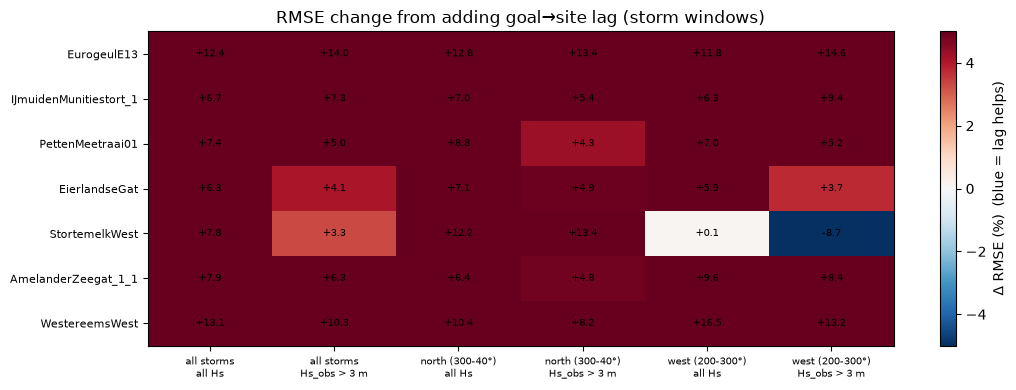

In [ ]:
pivot = lag_scores["Δrmse (%)"].unstack(["regime", "subset"]).loc[analysis_buoys]
pivot = pivot.dropna(axis=1, how="all")
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(pivot.values, cmap="RdBu_r", vmin=-5, vmax=5, aspect="auto")
ax.set_xticks(
    range(pivot.shape[1]), [f"{a}\n{b}" for a, b in pivot.columns], fontsize=7
)
ax.set_yticks(range(pivot.shape[0]), pivot.index, fontsize=8)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(
            j, i, f"{pivot.values[i, j]:+.1f}", ha="center", va="center", fontsize=7
        )
plt.colorbar(im, ax=ax, label="Δ RMSE (%)  (blue = lag helps)")
ax.set_title("RMSE change from adding goal→site lag (storm windows)")
plt.tight_layout()
plt.show()

## 7 · Storm case studies

For each storm: WHACS Hs along the boundary goals (top), buoy vs reconstruction at the
southern and northern buoys (middle), and periods (bottom — buoy **Tm-10** against Tm-10
computed from the reconstructed spectra, plus WHACS Tp at the feeding goal). The
reconstruction is also re-run with the **CODEC water level** at each goal instead of
`wl = 0` (the metamodel was trained over wl ∈ [-3.5, 3.5] m), to test whether surge
explains the missing peak height.

In [ ]:
def predict_goal_wl(
    offshore_t: xr.Dataset, wl: xr.DataArray, goal, models
) -> xr.Dataset | None:
    # As mm._predict_offshore(partition=-1) but with a time-varying water level
    df, hs_off = mm._offshore_forcing(offshore_t, goal, partition=mm.BULK_PARTITION)
    df["wl"] = wl.sel(goal=int(goal)).reindex(time=df.index).values.clip(-3.5, 3.5)
    valid = (
        mm._valid_timesteps(df, hs_off, mm.BULK_PARTITION, goal=goal) & df["wl"].notna()
    )
    if not valid.any():
        return None
    pred = mm.predict(
        goal,
        mda_n,
        df.loc[valid],
        models=models,
        pca_variance=pca_variance,
        sites=sites,
        row_dim="time",
    )
    pred["hs"] = pred["hs"] * hs_off.sel(time=pred.time)
    return pred


def tm_10(efth: xr.DataArray) -> xr.DataArray:
    # Tm-10 = m_-1 / m_0 from a (.., freq, dir) spectrum
    ef = efth.sum("dir") * np.deg2rad(float(efth.dir.diff("dir")[0]))
    f = ef.freq
    return (ef / f).integrate("freq") / ef.integrate("freq")


case_windows = {}
for name in case_storms:
    pk = storm_table.loc[storm_table.set == f"case: {name}", "peak"].iloc[0]
    case_windows[name] = slice(pk - pd.Timedelta("36h"), pk + storm_half_window[1])

storm_runs = {}
for name, tw in case_windows.items():
    wl_path = (
        storm_cache / f"storm_wl_n{mda_n}_{tw.start:%Y%m%d%H}_{tw.stop:%Y%m%d%H}.nc"
    )
    if not wl_path.is_file():
        off_t = offshore.sel(time=tw)
        chunks = []
        for g in mm._goals(None):
            models = mm.load_models(g, mda_n, pca_variance=pca_variance)
            p = predict_goal_wl(off_t, codec_wl.sel(time=tw), g, models)
            if p is not None:
                chunks.append(p.expand_dims(goal=[int(g)]).load())
            del models
            mm._release_gp_memory()
        xr.concat(chunks, dim="goal", join="outer").to_netcdf(wl_path)
    cube_wl = xr.open_dataset(wl_path).load()

    # the case-study window sits inside its (contiguous) storm-set window
    win = storm_table[storm_table.set == f"case: {name}"].iloc[0]
    cw = slice(win.start, win.stop)
    c0 = cube.sel(time=tw)
    c1 = apply_lag(cube.sel(time=cw), tau.sel(time=cw)).sel(time=tw)
    run = {}
    for label, cc in [("no lag", c0), ("lag", c1), ("wl CODEC", cube_wl)]:
        r, spec = mm._wavespectra_sum(
            cc.expand_dims(partition=[-1]), sites, save_spectra=True
        )
        r["tm10"] = tm_10(spec["efth"])
        run[label] = r.assign_coords(
            sites=[s.removeprefix("buoy_") for s in r.sites.values]
        )
    storm_runs[name] = run

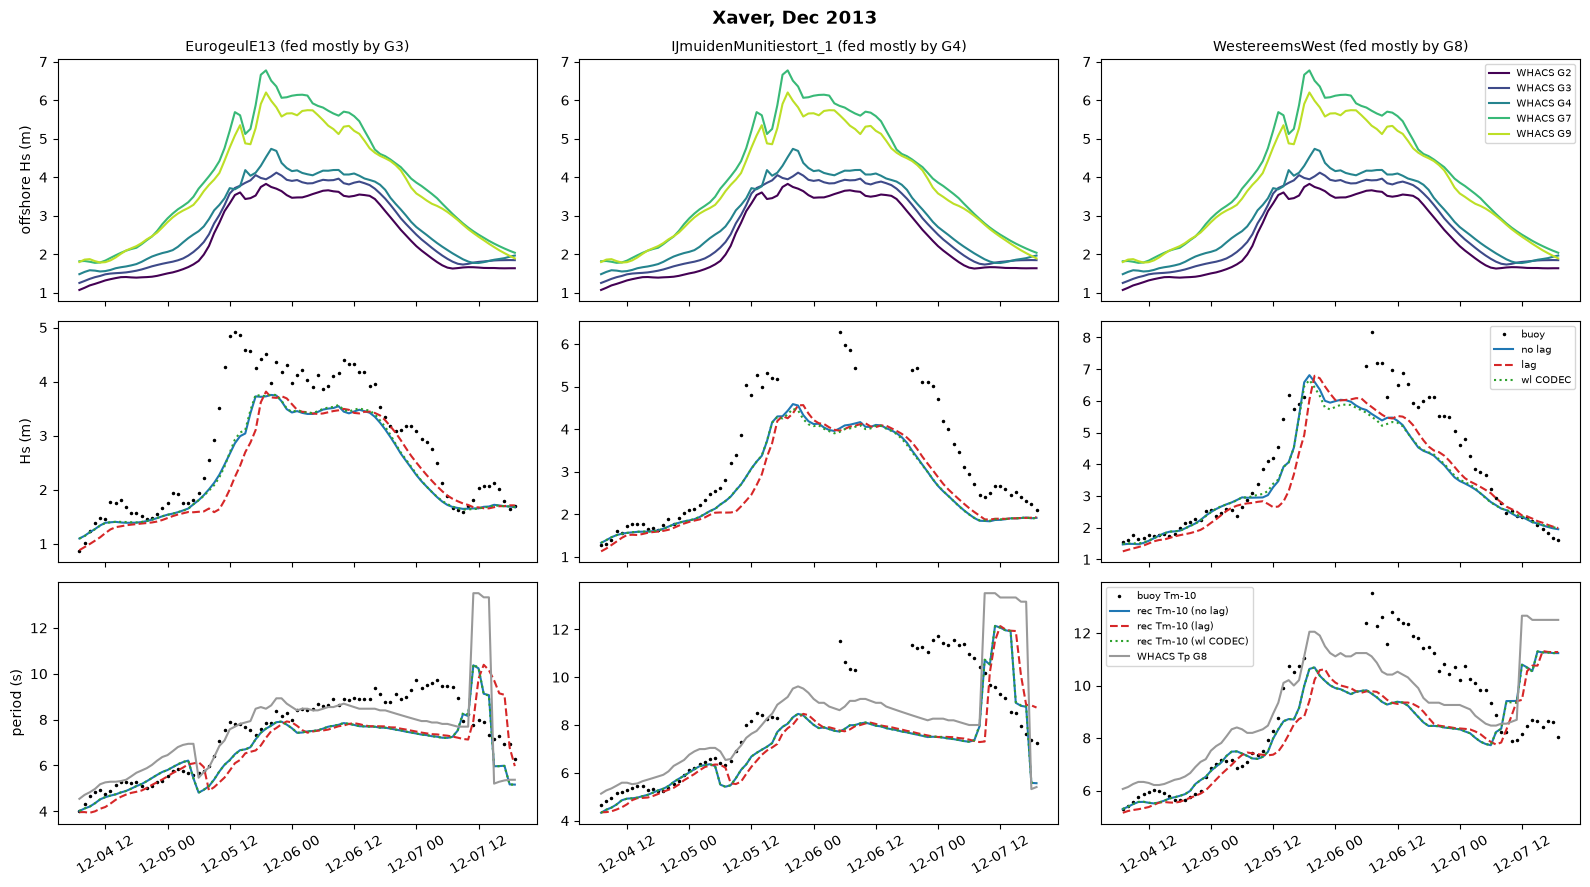

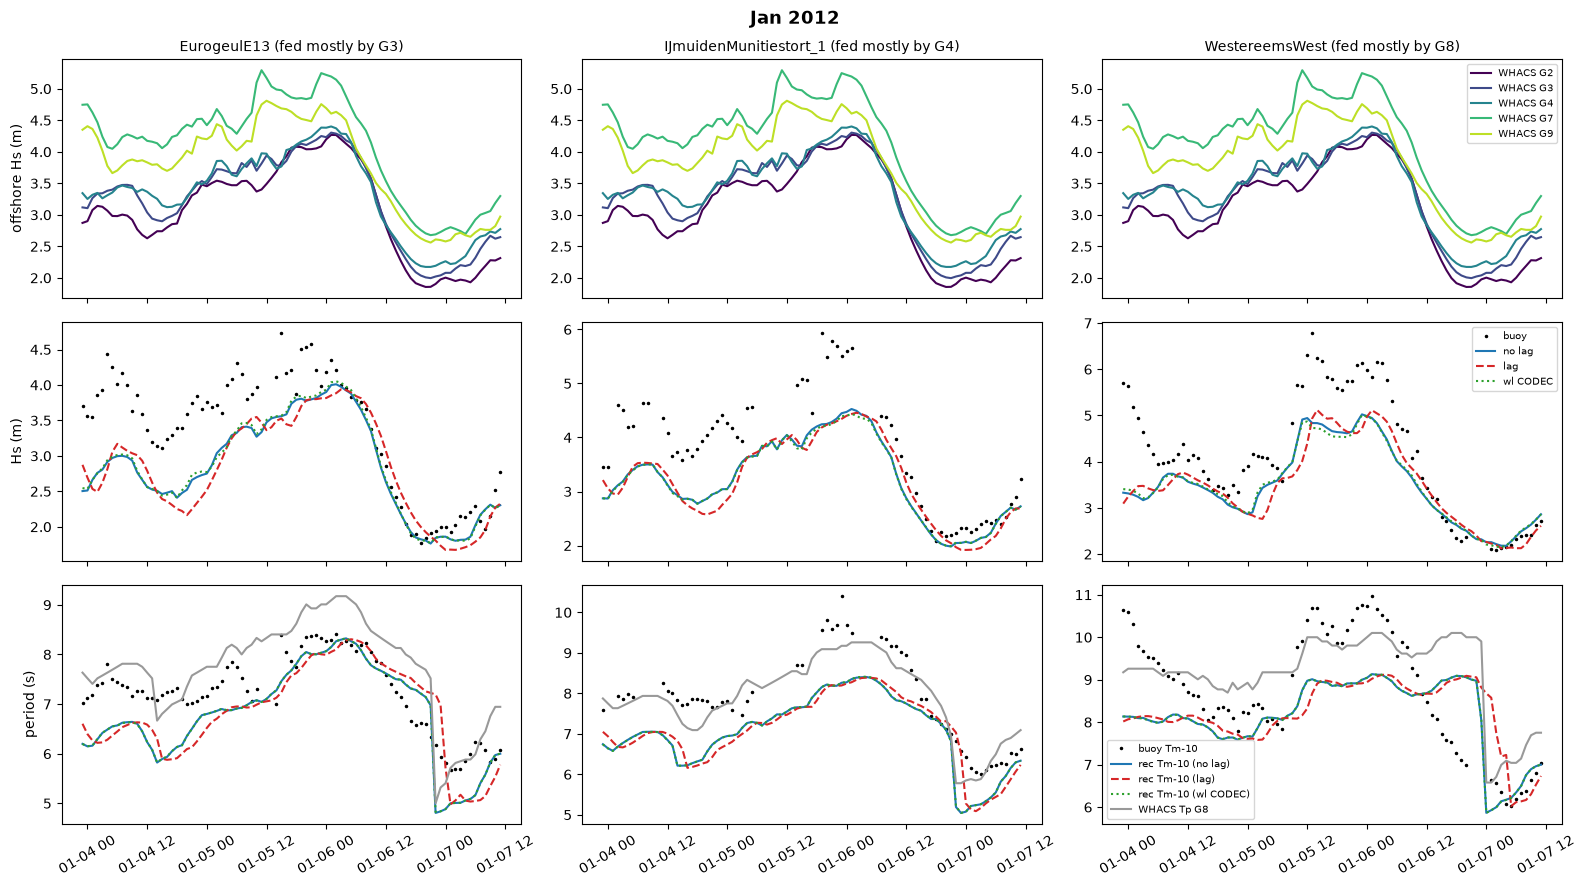

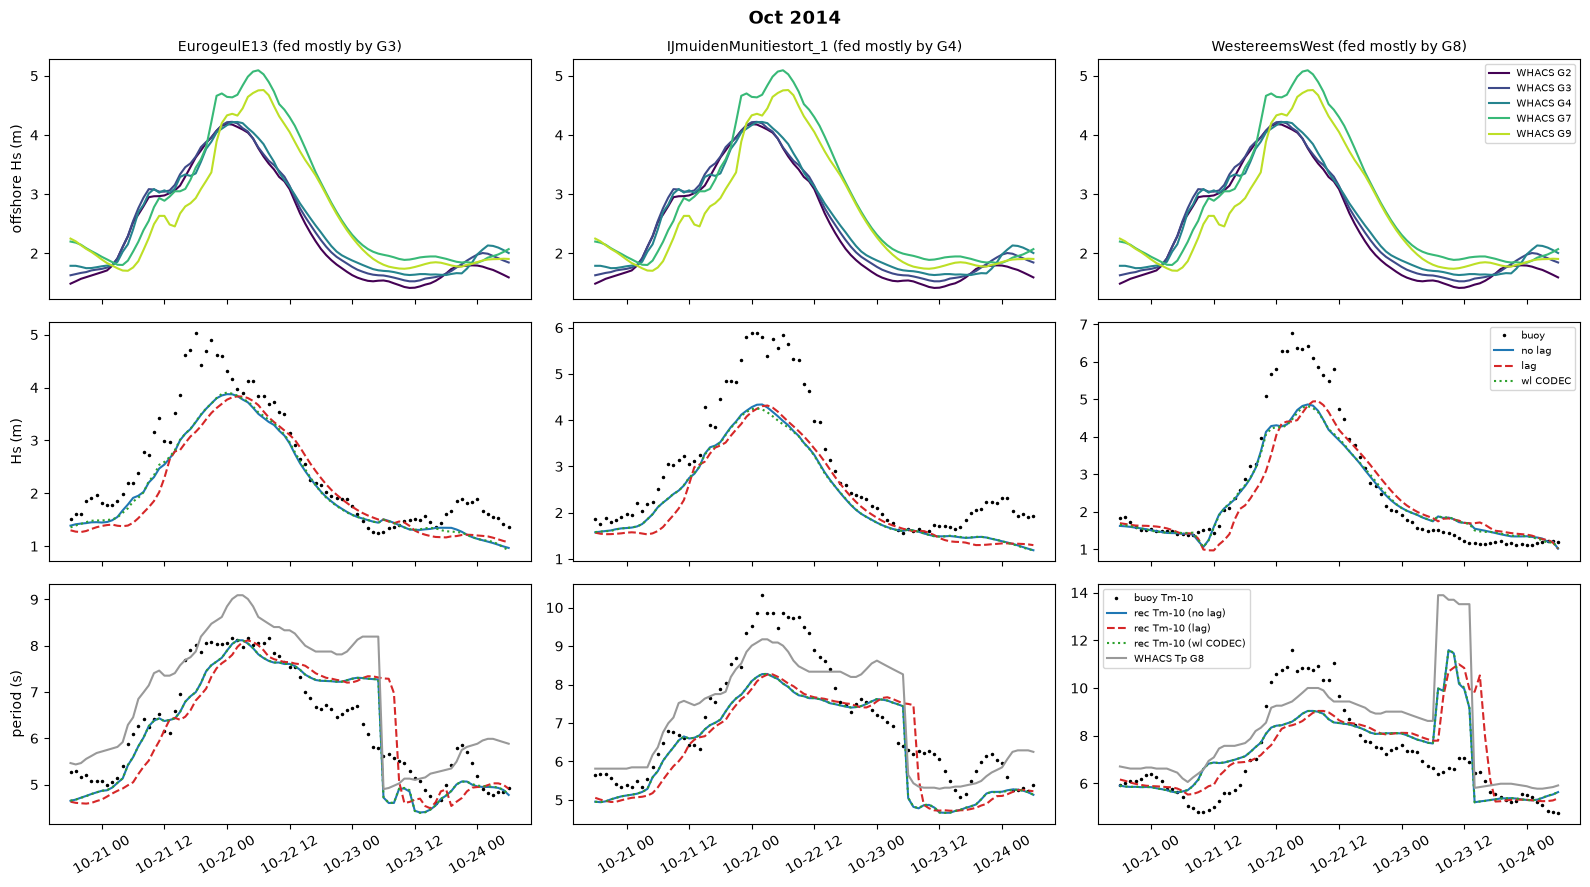

In [ ]:
feed_goal = {
    b: int(shares["north (300-40°)"].sel(sites=f"buoy_{b}").idxmax("goal"))
    for b in analysis_buoys
}
show_buoys = ["EurogeulE13", "IJmuidenMunitiestort_1", "WestereemsWest"]
styles = {
    "no lag": dict(color="tab:blue"),
    "lag": dict(color="tab:red", ls="--"),
    "wl CODEC": dict(color="tab:green", ls=":"),
}

for name, tw in case_windows.items():
    run = storm_runs[name]
    fig, axes = plt.subplots(3, len(show_buoys), figsize=(16, 9), sharex=True)
    for j, b in enumerate(show_buoys):
        ax = axes[0, j]
        for g, col in zip([2, 3, 4, 7, 9], plt.cm.viridis(np.linspace(0, 0.9, 5))):
            ax.plot(
                whacs.time.sel(time=tw),
                whacs["hs"].sel(goal=g, time=tw),
                color=col,
                label=f"WHACS G{g}",
            )
        ax.set_title(f"{b} (fed mostly by G{feed_goal[b]})", fontsize=10)
        ax = axes[1, j]
        ax.plot(obs_hs[b][tw], "k.", ms=3, label="buoy")
        for label, r in run.items():
            ax.plot(r.time, r["hs"].sel(sites=b), label=label, **styles[label])
        ax = axes[2, j]
        if b in obs_tm10:
            ax.plot(obs_tm10[b][tw], "k.", ms=3, label="buoy Tm-10")
        for label, r in run.items():
            ax.plot(
                r.time,
                r["tm10"].sel(sites=b),
                label=f"rec Tm-10 ({label})",
                **styles[label],
            )
        ax.plot(
            whacs.time.sel(time=tw),
            whacs["tp"].sel(goal=feed_goal[b], time=tw),
            color="0.6",
            label=f"WHACS Tp G{feed_goal[b]}",
        )
        ax.tick_params(axis="x", rotation=30)
    axes[0, 0].set_ylabel("offshore Hs (m)")
    axes[1, 0].set_ylabel("Hs (m)")
    axes[2, 0].set_ylabel("period (s)")
    axes[0, -1].legend(fontsize=7)
    axes[1, -1].legend(fontsize=7)
    axes[2, -1].legend(fontsize=7)
    fig.suptitle(f"{name}", fontsize=13, weight="bold")
    plt.tight_layout()
    plt.show()

In [ ]:
rows = []
for name, tw in case_windows.items():
    for label, r in storm_runs[name].items():
        for b in analysis_buoys:
            o = obs_hs[b][tw]
            rr = r["hs"].sel(sites=b).to_series().reindex(o.index)
            if o.notna().sum() < 24:
                continue
            s = scores(o, rr, pd.Series(True, index=o.index))
            tm_o = obs_tm10[b][tw] if b in obs_tm10 else None
            tm_r = r["tm10"].sel(sites=b).to_series().reindex(o.index)
            rows.append(
                {
                    "storm": name,
                    "buoy": b,
                    "run": label,
                    "rmse": s["rmse"],
                    "bias": s["bias"],
                    "r": s["r"],
                    "peak obs": o.max(),
                    "peak rec": rr.max(),
                    "Tm-10 bias": (tm_r - tm_o).mean() if tm_o is not None else np.nan,
                }
            )
storm_scores = pd.DataFrame(rows).set_index(["storm", "buoy", "run"])
storm_scores.round(2)

rmse  bias     r  peak obs  peak rec  Tm-10 bias
storm           buoy                   run                                                       
Xaver, Dec 2013 EurogeulE13            no lag    0.68 -0.49  0.94      4.92      3.75       -0.71
                IJmuidenMunitiestort_1 no lag    1.09 -0.82  0.95      6.29      4.59       -1.10
                EierlandseGat          no lag    0.90 -0.66  0.95      6.23      5.21       -0.35
                StortemelkWest         no lag    0.51 -0.03  0.91      4.85      5.16       -0.48
                AmelanderZeegat_1_1    no lag    1.23 -0.94  0.96      7.44      6.42       -1.04
                WestereemsWest         no lag    0.94 -0.57  0.96      8.18      6.81       -0.67
                EurogeulE13            lag       0.81 -0.55  0.87      4.92      3.81       -0.68
                IJmuidenMunitiestort_1 lag       1.16 -0.89  0.95      6.29      4.56       -1.07
                EierlandseGat          lag       0.92 -0.67  0.93      6.23      5.16       -0.39
                StortemelkWest         lag       0.65 -0.10  0.86      4.85      5.16       -0.58
                AmelanderZeegat_1_1    lag       1.25 -0.97  0.96      7.44      6.37       -1.14
                WestereemsWest         lag       0.99 -0.65  0.95      8.18      6.79       -0.83
                EurogeulE13            wl CODEC  0.66 -0.48  0.94      4.92      3.76       -0.71
                IJmuidenMunitiestort_1 wl CODEC  1.10 -0.83  0.95      6.29      4.48       -1.10
                EierlandseGat          wl CODEC  0.89 -0.65  0.95      6.23      5.12       -0.35
                StortemelkWest         wl CODEC  0.49 -0.04  0.91      4.85      5.05       -0.48
                AmelanderZeegat_1_1    wl CODEC  1.27 -0.95  0.96      7.44      6.32       -1.04
                WestereemsWest         wl CODEC  0.94 -0.57  0.96      8.18      6.66       -0.67
Jan 2012        EurogeulE13            no lag    0.67 -0.52  0.87      4.73      4.01       -0.46
                IJmuidenMunitiestort_1 no lag    0.84 -0.70  0.95      5.93      4.53       -0.97
                PettenMeetraai01       no lag    0.99 -0.82  0.94      5.85      4.10       -0.73
                EierlandseGat          no lag    0.98 -0.84  0.94      5.88      4.47       -0.66
                StortemelkWest         no lag    0.63 -0.28  0.65      4.38      4.58       -0.90
                AmelanderZeegat_1_1    no lag    0.74 -0.60  0.95      6.30      5.09       -0.62
                WestereemsWest         no lag    0.89 -0.64  0.93      6.78      5.02       -0.62
                EurogeulE13            lag       0.73 -0.52  0.80      4.73      3.94       -0.42
                IJmuidenMunitiestort_1 lag       0.89 -0.72  0.90      5.93      4.46       -0.92
                PettenMeetraai01       lag       1.01 -0.83  0.90      5.85      4.05       -0.69
                EierlandseGat          lag       0.99 -0.85  0.92      5.88      4.44       -0.65
                StortemelkWest         lag       0.66 -0.29  0.64      4.38      4.52       -0.88
                AmelanderZeegat_1_1    lag       0.75 -0.59  0.93      6.30      5.09       -0.63
                WestereemsWest         lag       0.91 -0.64  0.90      6.78      5.12       -0.60
                EurogeulE13            wl CODEC  0.66 -0.50  0.87      4.73      4.05       -0.46
                IJmuidenMunitiestort_1 wl CODEC  0.85 -0.71  0.95      5.93      4.44       -0.96
                PettenMeetraai01       wl CODEC  0.97 -0.80  0.93      5.85      4.12       -0.73
                EierlandseGat          wl CODEC  0.97 -0.83  0.94      5.88      4.49       -0.67
                StortemelkWest         wl CODEC  0.61 -0.25  0.66      4.38      4.68       -0.90
                AmelanderZeegat_1_1    wl CODEC  0.75 -0.60  0.95      6.30      5.07       -0.63
                WestereemsWest         wl CODEC  0.90 -0.64  0.93      6.78      5.01       -0.62
Oct 2014        EurogeulE13    

## 8 · Conclusions

**1 · There is no timing error to correct in the bulk reconstruction.**
- Lagged correlation buoy vs reconstruction (2010–2015, Hs > 1.5 m) peaks at **|L| ≤ 0.4 h**
  at every buoy, for both the northern and the western regime (5a).
- Storm-peak timing (Hs > 2.5 m, gap-free peaks): median Δt = **0 h** for northern storms at
  every buoy (+0.5 h at Eurogeul); the reconstruction is not systematically early (5b).

**2 · Why the "north → south" path doesn't show up.**
- The southern buoys are fed by the **nearest western goals**, also in northern storms:
  Eurogeul ≈ 0.87 of its energy from G1–G3, IJmuiden ≈ 0.85 from G3–G4; G6–G10 contribute
  ~0 (section 3). SnapWave refraction and the coastline already route the energy, so the
  250 km path from G7 is never taken *inside* the AoI.
- WHACS already carries what happens outside: G7 → G2 shows only a **~0.7 h** shift over 274 km
  (section 4). A swell would need 7–8 h for that, so storm Hs here is a **synoptic, wind-driven
  field** that grows nearly at the same time over the whole southern North Sea. It is not a wave
  train travelling down from the north.

**3 · Adding the physical lag makes it worse.** The goal→site lag (energy-weighted τ ≈
1–3 h, section 6) **increases RMSE by 4–14 % at every buoy** in the 13 storms and lowers
correlation. The metamodel cases have no wind, so the boundary value at time *t* works as a
proxy for the local wind sea at time *t*. Delaying it breaks that synchrony. In Xaver the rising
limb is already slightly *late* in the reconstruction, and the lag delays it further.

**4 · The real storm-peak problem is amplitude and period, coming from the forcing.**
- The reconstructed peak is **~0.7–0.9 × the observed peak** (median by buoy and regime), and
  the bias for Hs_obs > 3 m is −0.1 to −1.1 m.
- Tm-10 is underestimated by **0.4–1.1 s** in the case-study storms.
- A **time-varying water level** (CODEC at each goal instead of wl = 0) changes the storm
  RMSE by ≤ 0.02 m, so these buoys are not depth-limited and surge is not the explanation.
- In **Xaver** the buoys stay high on 6–7 Dec with **Tm-10 ≈ 11–13 s** (long northern swell),
  while WHACS bulk Tp at the feeding goals stays ~8–10 s and only switches to the long swell
  around 7 Dec 06:00, about a day later, once the wind sea has decayed. WHACS has a single
  partition through most of the storm, so neither bulk nor partition mode can pass that swell
  on. The reconstruction decays too early because the **boundary forcing** decays too early.

**Recommendation.** Do not add a propagation lag to the Netherlands reconstruction. At most,
keep it as an option for long-period swell partitions in spectral mode, for cases with large
open boundaries and little local wind. The storm-peak deficit is where the gains are:
(i) check WHACS at the goals against an offshore reference (e.g. platform buoys) during
these storms; (ii) consider a storm/peak bias correction, or local wind growth in the
SnapWave cases; (iii) re-check partition mode once the boundary has separate swell partitions.
